# ANN Data Preparation

Load the cleaned dataset, create stratified splits, and preprocess features. The next step is to wrap these splits in a PyTorch `Dataset` and `DataLoader`.

## Load and inspect data

Load the cleaned dataset and review a sample and its schema.

In [73]:
import re



def drive_to_direct_url(link: str) -> str:
    """
    Convert Google Drive share link to direct download URL.
    Works for multiple link formats.
    """
    patterns = [
        r"/file/d/([a-zA-Z0-9_-]+)",
        r"id=([a-zA-Z0-9_-]+)",
        r"/open\?id=([a-zA-Z0-9_-]+)",
    ]

    file_id = None

    for pattern in patterns:
        match = re.search(pattern, link)
        if match:
            file_id = match.group(1)
            break

    if not file_id:
        raise ValueError("Invalid Google Drive link")

    return f"https://drive.google.com/uc?id={file_id}"

In [74]:
clean_dataset_drive_url = (
    "https://drive.google.com/file/d/1AxchD_W4q0d9lXBOi2gyqunl_TmH3ktm/view?usp=sharing"
)
dataset = drive_to_direct_url(clean_dataset_drive_url)

In [75]:
import pandas as pd

df = pd.read_csv(dataset)

In [76]:
df.head()

,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,Female,66,110,73,5.88,25.75,0,0,0,0,0,No
1,35,Female,60,125,68,5.71,19.58,0,0,0,0,0,No
2,62,Female,57,127,74,6.85,20.24,0,0,0,0,0,No
3,73,Male,55,193,112,6.28,21.72,0,0,0,0,0,No
4,68,Female,71,150,81,5.71,17.79,0,0,0,0,0,No


In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5261 entries, 0 to 5260
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     5261 non-null   int64  
 1   gender                  5261 non-null   object 
 2   pulse_rate              5261 non-null   int64  
 3   systolic_bp             5261 non-null   int64  
 4   diastolic_bp            5261 non-null   int64  
 5   glucose                 5261 non-null   float64
 6   bmi                     5261 non-null   float64
 7   family_diabetes         5261 non-null   int64  
 8   hypertensive            5261 non-null   int64  
 9   family_hypertension     5261 non-null   int64  
 10  cardiovascular_disease  5261 non-null   int64  
 11  stroke                  5261 non-null   int64  
 12  diabetic                5261 non-null   object 
dtypes: float64(2), int64(9), object(2)
memory usage: 534.4+ KB


## Split and encode

Separate the target, encode its labels, and create stratified train, validation, and test splits.

In [78]:
X = df.drop(columns="diabetic")
y = df["diabetic"]

In [79]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

In [80]:
from sklearn.model_selection import train_test_split


X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

## Preprocess features

Fit scaling and categorical encoding on the training split, then apply them to validation and test data.

In [81]:
numeric_cols = X_train.select_dtypes(include="number").columns
categorical_cols = X_train.select_dtypes(exclude="number").columns

In [82]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    [
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ]
)


In [83]:
X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)

In [84]:
input_features = X_train.shape[1]

In [85]:
import torch

In [86]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

device

device(type='cuda')

In [87]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32, device=device)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32, device=device)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32, device=device)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32, device=device).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32, device=device).reshape(-1, 1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32, device=device).reshape(-1, 1)

In [88]:
from torch.utils.data import TensorDataset

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [89]:
from torch.utils.data import DataLoader

In [90]:
BATCH_SIZE = 32
LEARNING_RATE = 0.001
EPOCHS = 100

In [91]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [92]:
import torch.nn as nn


model = nn.Sequential(
    nn.Linear(input_features, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1),
).to(device)

In [93]:
criterion = nn.BCEWithLogitsLoss()

In [94]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [95]:


train_losses = []

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:
        # Forward pass
        outputs = model(X_batch)

        # Calculate loss
        loss = criterion(outputs, y_batch.float())

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_loss)

    print(f"Epoch [{epoch + 1}/{EPOCHS}], Train Loss: {epoch_loss:.4f}")

Epoch [1/100], Train Loss: 0.3189
Epoch [2/100], Train Loss: 0.1752
Epoch [3/100], Train Loss: 0.1683
Epoch [4/100], Train Loss: 0.1654
Epoch [5/100], Train Loss: 0.1643
Epoch [6/100], Train Loss: 0.1639
Epoch [7/100], Train Loss: 0.1613
Epoch [8/100], Train Loss: 0.1615
Epoch [9/100], Train Loss: 0.1602
Epoch [10/100], Train Loss: 0.1585
Epoch [11/100], Train Loss: 0.1600
Epoch [12/100], Train Loss: 0.1590
Epoch [13/100], Train Loss: 0.1567
Epoch [14/100], Train Loss: 0.1556
Epoch [15/100], Train Loss: 0.1553
Epoch [16/100], Train Loss: 0.1552
Epoch [17/100], Train Loss: 0.1545
Epoch [18/100], Train Loss: 0.1531
Epoch [19/100], Train Loss: 0.1536
Epoch [20/100], Train Loss: 0.1512
Epoch [21/100], Train Loss: 0.1509
Epoch [22/100], Train Loss: 0.1508
Epoch [23/100], Train Loss: 0.1506
Epoch [24/100], Train Loss: 0.1512
Epoch [25/100], Train Loss: 0.1487
Epoch [26/100], Train Loss: 0.1474
Epoch [27/100], Train Loss: 0.1467
Epoch [28/100], Train Loss: 0.1469
Epoch [29/100], Train Loss: 0

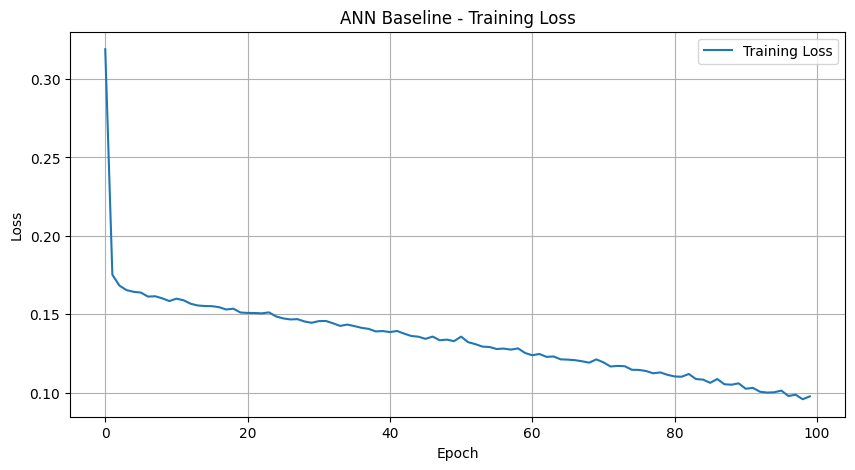

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Baseline - Training Loss")

plt.legend()
plt.grid(True)
plt.show()

In [97]:
best_epoch = train_losses.index(min(train_losses)) + 1
best_train_loss = min(train_losses)

print(f"Best Epoch: {best_epoch}")
print(f"Best Training Loss: {best_train_loss:.4f}")

Best Epoch: 99
Best Training Loss: 0.0959


In [98]:
model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs = model(X_batch).squeeze(1)

        probabilities = torch.sigmoid(outputs)
        predictions = (probabilities >= 0.5).int()

        y_true.extend(y_batch.cpu().numpy().ravel())
        y_pred.extend(predictions.cpu().numpy().ravel())
        y_prob.extend(probabilities.cpu().numpy().ravel())

In [99]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_true, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_true, y_prob):.4f}")
print(f"PR-AUC:    {average_precision_score(y_true, y_prob):.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

Accuracy:  0.9392
Precision: 0.6000
Recall:    0.2308
F1 Score:  0.3333
ROC-AUC:   0.7688
PR-AUC:    0.3431

Classification Report:
              precision    recall  f1-score   support

         0.0       0.95      0.99      0.97       738
         1.0       0.60      0.23      0.33        52

    accuracy                           0.94       790
   macro avg       0.77      0.61      0.65       790
weighted avg       0.93      0.94      0.93       790

